In [1]:
import numpy as np
import pandas as pd
import os
from matplotlib import pyplot as plt
import json
import csv
import os
import scipy as sp
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import cosine_similarity
# from geomstats.geometry.spd_matrices import SPDMatrices
from pyriemann.utils.distance import distance_riemann
from pyriemann.utils.distance import pairwise_distance


In [2]:
# !pip install geomstats

In [3]:
# !pip install pyriemann

In [4]:
mat_data = r"..//data//10 Agents//p5//Set1.mat" 
data = sp.io.loadmat(mat_data)
#extract data

gamma_list = data["Phi"][0] ## hessian for each agent local function ## they are symetric

theta_list = [np.asarray(t).reshape(-1) for t in data["theta"][0]] ## theta of the f_i(x_i) = (x_i-theta_i) @ phi @ (x_i-theta_i)

In [5]:
data.keys()

dict_keys(['__header__', '__version__', '__globals__', 'J_solver', 'Phi', 'options', 'solution', 'theta', '__function_workspace__'])

In [6]:
gamma_list[0].shape[1]

5

In [7]:
theta_list

[array([-0.03345266, -0.53253588, -0.88109121,  0.58714854, -0.03083774]),
 array([-0.50547131,  0.16799992,  0.82157632,  0.23016336, -0.21423052]),
 array([-0.25333721, -0.1339    ,  1.07536545, -0.404644  ,  0.63198252]),
 array([ 0.24372939,  0.24004416, -0.54044135,  0.38052753,  0.37661806]),
 array([ 0.11960479, -0.90129855,  1.02434044, -0.11828353, -0.84201805]),
 array([-0.71069152,  0.70234596,  0.77777108, -0.35627698,  0.07108074]),
 array([ 0.17108845,  0.87064114, -0.55564988,  0.05652146,  0.63893662]),
 array([-0.42280241, -0.02674546, -0.51176077,  0.47828866, -0.74241106]),
 array([-0.67565254, -0.09766349, -0.53853028,  0.36140033,  1.03151262]),
 array([-0.53000393,  0.21019111, -0.08358643,  0.25218232, -0.17904571])]

<function matplotlib.pyplot.show(close=None, block=None)>

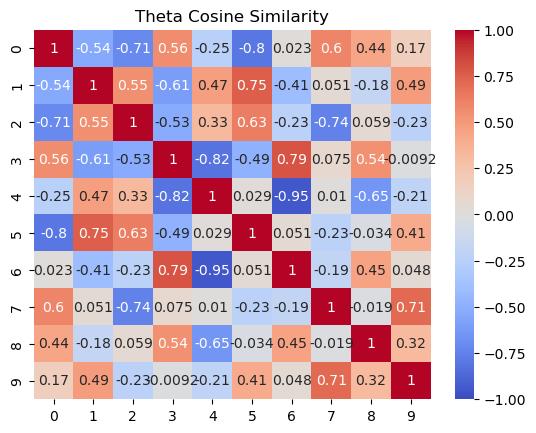

In [8]:
## similarity matrix using the consine similarity

theta_similarity = cosine_similarity(theta_list, theta_list)
sns.heatmap(theta_similarity, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Theta Cosine Similarity")
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

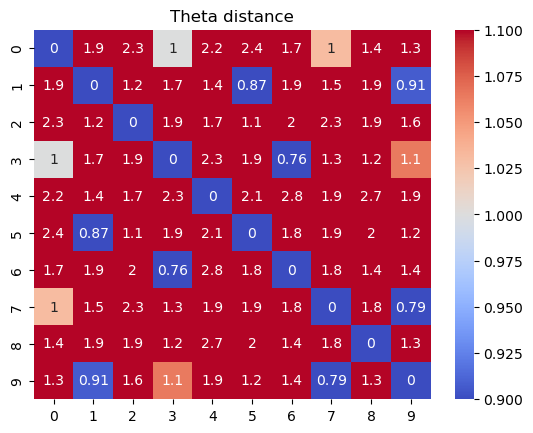

In [9]:
from sklearn.metrics import pairwise_distances

theta_array = np.vstack(theta_list)
theta_dist = pairwise_distances(theta_array, metric="euclidean")
sns.heatmap(theta_dist, annot=True, cmap='coolwarm', vmin=1, vmax=1)
plt.title("Theta distance")
plt.show

In [10]:
# cluster

kmeans = KMeans(n_clusters=4, random_state=0).fit(theta_list)
print(kmeans.labels_)

[1 0 0 2 3 0 2 1 2 1]


C:\Users\dvu29\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [11]:
# Hession similarity
# 1. Coefficient
# 2. Riemmannian distance between Hessian matrix

In [12]:
dist = distance_riemann(gamma_list[6], gamma_list[9])
print(f"Riemannian distance: {dist}")

Riemannian distance: 1.813776858351096


In [13]:
dist = distance_riemann(gamma_list[8], gamma_list[9])
print(f"Riemannian distance: {dist}")

Riemannian distance: 1.6916986086956036


In [14]:
gamma_list

array([array([[ 3.05271894,  0.00511058,  0.75442126,  0.10518988,  0.39036285],
              [ 0.00511058,  1.2829242 ,  0.31232697, -0.23996578,  0.16239734],
              [ 0.75442126,  0.31232697,  2.35086902,  0.16726005,  0.02007351],
              [ 0.10518988, -0.23996578,  0.16726005,  3.4452551 ,  0.2774467 ],
              [ 0.39036285,  0.16239734,  0.02007351,  0.2774467 ,  1.44179101]]),
       array([[ 1.8543407 ,  0.29833952, -0.93124254,  0.43258215,  0.1533364 ],
              [ 0.29833952,  2.96153576,  0.58298475,  0.14334996,  0.05268313],
              [-0.93124254,  0.58298475,  3.04529189,  0.52067856,  0.04610029],
              [ 0.43258215,  0.14334996,  0.52067856,  3.00197641,  0.05121138],
              [ 0.1533364 ,  0.05268313,  0.04610029,  0.05121138,  2.77931379]]),
       array([[ 2.25733269, -0.27961669, -0.41232016,  0.43519568, -0.44246965],
              [-0.27961669,  3.44965339,  0.55044586,  0.2410538 ,  0.83532871],
              [-0.412320

In [15]:
X = np.array([np.diag(1 + np.random.rand(3)) for _ in range(10)]) 
X.shape

(10, 3, 3)

In [16]:
gamma_matrix_list = np.array([gamma_list[i] for i in range(len(gamma_list))])

In [17]:
gamma_matrix_list.shape

(10, 5, 5)

In [18]:
dist_matrix = pairwise_distance(gamma_matrix_list, metric='riemann')
print(dist_matrix.shape)
print(dist_matrix)

(10, 10)
[[5.29193369e-15 1.79408287e+00 1.78171028e+00 1.47522073e+00
  1.42707302e+00 1.63754508e+00 1.68709937e+00 1.51484619e+00
  1.55878917e+00 1.56473387e+00]
 [1.79408287e+00 2.37078762e-15 1.12026892e+00 1.54634404e+00
  1.82955532e+00 1.57660872e+00 1.51364255e+00 2.00789636e+00
  1.67706919e+00 1.57629901e+00]
 [1.78171028e+00 1.12026892e+00 6.52297364e-15 1.65435698e+00
  1.61758766e+00 1.91892893e+00 1.59483827e+00 1.96297153e+00
  1.94191129e+00 1.64790963e+00]
 [1.47522073e+00 1.54634404e+00 1.65435698e+00 3.92523115e-15
  1.36089670e+00 1.16808701e+00 1.17164011e+00 1.86377459e+00
  1.55421487e+00 1.58843320e+00]
 [1.42707302e+00 1.82955532e+00 1.61758766e+00 1.36089670e+00
  3.83629851e-15 1.44859811e+00 1.28068269e+00 1.31708500e+00
  1.39471876e+00 1.48459565e+00]
 [1.63754508e+00 1.57660872e+00 1.91892893e+00 1.16808701e+00
  1.44859811e+00 4.89758123e-15 1.38635747e+00 1.73711612e+00
  1.07685862e+00 1.60623006e+00]
 [1.68709937e+00 1.51364255e+00 1.59483827e+00 1.

<function matplotlib.pyplot.show(close=None, block=None)>

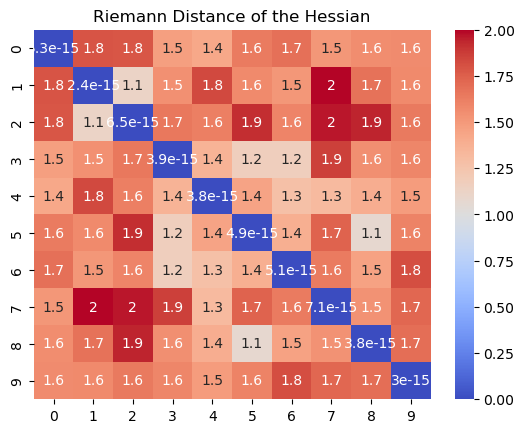

In [19]:
sns.heatmap(dist_matrix, annot=True, cmap='coolwarm', vmin=0, vmax=2)
plt.title("Riemann Distance of the Hessian")
plt.show

In [20]:
## clustering 
# from sklearn.cluster import AgglomerativeClustering
# from scipy.cluster.hierarchy import dendrogram

# clustering = AgglomerativeClustering(n_)

## Generating the function with cluster

In [21]:
# generate K distinct base Gamma and Theta

def make_spd(M, eig_floor, jitter=1e-12):
    # project the symetric matrix to SPD by shifting eigenvalues if needed

    # make symetric matrix
    A = 0.5 * (M + M.T)

    # min eig values
    eig_values = np.linalg.eigvalsh(A) ## can use the eigvals but this one more stable and faster
    
    if np.min(eig_values) <= eig_floor:
        A = A + (eig_floor - min(eig_values) + jitter) * np.eye(A.shape[0])
        
    return A

In [22]:
## generate the random uniform matrix
def rand_unform_matrix(rng, shape, low, high):
    return rng.uniform(low, high, size=shape)

def rand_uniform_vector(rng, size, low, high):
    return rng.uniform(low, high, size=size)

In [23]:
def generate_clustered_quadratics(
    n, 
    p, 
    K,
    mode = "both", # here can change to "theta_only", "gamma_only", "both" or "none"
    theta_sep = 5.0, 
    theta_noise = 0.1, 
    gamma_noise = 0.1, 
    eig_floor = 2.0,
    balanced = True,
    low = -0.5,
    high = 0.5,
    seed=None):

    # generate the theta and gamma for the quadratic function f(x_i) = (x_i - theta_i)^T@Gamma_i@(x_i - theta_i) 
    # gamma_i is sym pos def

    rng = np.random.default_rng(seed)

    Gamma = []
    theta = []

    Gamma_proto = []
    theta_proto = []

    # base
    theta_base = rng.uniform(low, high, size=p) # start center

    A0 = rng.uniform(low, high, size=(p, p)) # start gamma
    Gamma_base = 0.5 * (A0 + A0.T) # get symetric
    Gamma_base = make_spd(Gamma_base, eig_floor=eig_floor) # scale

    # generate the prototype for each cluster
    for k in range(K):
        
        # theta prototype
        if mode in {"theta_only", "both"}: ## cluster differ theta but may similar base Gamma
            
            # if both -> each cluster have diff base theta
            direction = rng.uniform(low, high, size=p) # rv direction
            
            norm_dir = np.linalg.norm(direction)
            
            if norm_dir < 1e-12:
                direction = np.ones(p) / np.sqrt(p)
        
            else:
                direction = direction / norm_dir # get unit direction

            theta_k = theta_base + theta_sep * (k + 1) * direction
        
        else: # none -> each cluster have same theta_base -> only adding rand noise for each func in each cluster theta 
            theta_k = theta_base.copy()

        # Gamma prototype
        if mode in {"gamma_only", "both"}: # each cluster have same theta just diff gamma or if both mode is consdier -> also theta change
            
            # if both -> each cluster have diff base Gamma
            
            A = rng.uniform(low, high, size=(p, p))
            Gamma_k = 0.5 * (A + A.T)
            Gamma_k = make_spd(Gamma_k, eig_floor=eig_floor)
        else: # none mode -> each cluster have same gamma_base -> only add the rand noise for each func in each each cluster gamma
            Gamma_k = Gamma_base.copy()

        theta_proto.append(theta_k)
        Gamma_proto.append(Gamma_k)

    # assign label for each func
    if balanced:
        counts = [n // K] * K
        
        # balance the number of each member each cluster
        
        for i in range(n % K):
            counts[i] += 1

        labels = []
        
        for k, c in enumerate(counts):
            labels.extend([k] * c)
            
        # get label but in order 
        
        labels = np.array(labels, dtype=int)
        # shuffle the label a bit
        rng.shuffle(labels)
    else:
        labels = rng.integers(low=0, high=K, size=n)

    # generate samples around prototypes for each cluster
    for i in range(n):
        k = labels[i]

        # theta_i near theta prototype
        
        # theta_perturb = rng.uniform(-theta_noise, theta_noise, size=p) # uniform noise

        # gaussian noise
        theta_perturb = theta_noise * rng.normal(size=p)
        
        theta_i = theta_proto[k] + theta_perturb # add noise to each theta

        # Gamma_i near Gamma prototype
        # E = rng.uniform(-gamma_noise, gamma_noise, size=(p, p)) # uniform noise

        # gaussian noise
        E = gamma_noise * rng.normal(size=(p, p))
        
        E = 0.5 * (E + E.T)
        Gamma_i = Gamma_proto[k] + E # random psd noise for the Gamma and refine if it affect their eigval
        Gamma_i = make_spd(Gamma_i, eig_floor=eig_floor)

        theta.append(theta_i)
        Gamma.append(Gamma_i)

    return Gamma, theta, labels, Gamma_proto, theta_proto

In [24]:
rng = np.random.default_rng(None)

In [25]:

rng.uniform(-0.1, 0.1, size=5)

array([-0.06320176,  0.09711678,  0.06644792,  0.05024927,  0.01291297])

In [26]:
Gamma, theta, labels, Gamma_proto, theta_proto = generate_clustered_quadratics(
    10, 
    5, 
    2,
    mode = "both",
    theta_sep = 1.0, 
    theta_noise = 0.1, 
    gamma_noise = 0.1, 
    eig_floor = 1.0,
    balanced = True,
    low = -1,
    high = 1,
    seed=0)

In [27]:
def quadratic_value(x, theta, Gamma):
    d = x - theta
    return d.T @ Gamma @ d

In [28]:
gamma_matrix_list = np.array([Gamma[i] for i in range(len(Gamma))])

In [29]:
dist_gamma_matrix = pairwise_distance(gamma_matrix_list, metric='riemann')
print(dist_gamma_matrix.shape)
print(dist_gamma_matrix)

(10, 10)
[[2.98317567e-15 1.15345866e+00 2.77517420e-01 2.32552773e-01
  1.02345941e+00 2.63862246e-01 1.05874572e+00 1.11503798e+00
  2.47317917e-01 1.09066921e+00]
 [1.15345866e+00 2.67377111e-15 1.20613205e+00 1.15376329e+00
  3.46221253e-01 1.17791000e+00 3.78263599e-01 1.95287956e-01
  1.08240329e+00 2.39492693e-01]
 [2.77517420e-01 1.20613205e+00 2.81743019e-15 3.25405832e-01
  1.04739711e+00 2.25667952e-01 1.11876356e+00 1.16327156e+00
  3.42407545e-01 1.14316732e+00]
 [2.32552773e-01 1.15376329e+00 3.25405832e-01 3.15193861e-15
  1.02847560e+00 2.09745799e-01 1.06438892e+00 1.11484139e+00
  2.19596688e-01 1.09232168e+00]
 [1.02345941e+00 3.46221253e-01 1.04739711e+00 1.02847560e+00
  4.99476988e-15 1.03200077e+00 3.04230246e-01 3.25812712e-01
  9.54280234e-01 2.23792902e-01]
 [2.63862246e-01 1.17791000e+00 2.25667952e-01 2.09745799e-01
  1.03200077e+00 4.93518799e-15 1.07520418e+00 1.13314861e+00
  3.02294796e-01 1.11593132e+00]
 [1.05874572e+00 3.78263599e-01 1.11876356e+00 1.

In [30]:
gamma_matrix_list.shape

(10, 5, 5)

<function matplotlib.pyplot.show(close=None, block=None)>

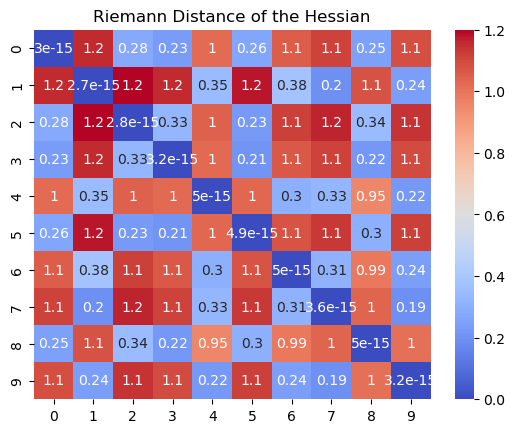

In [33]:
sns.heatmap(dist_gamma_matrix, annot=True, cmap='coolwarm', vmin=0, vmax=1.2)
plt.title("Riemann Distance of the Hessian")
plt.show

In [34]:
labels

array([0, 1, 0, 0, 1, 0, 1, 1, 0, 1])

<function matplotlib.pyplot.show(close=None, block=None)>

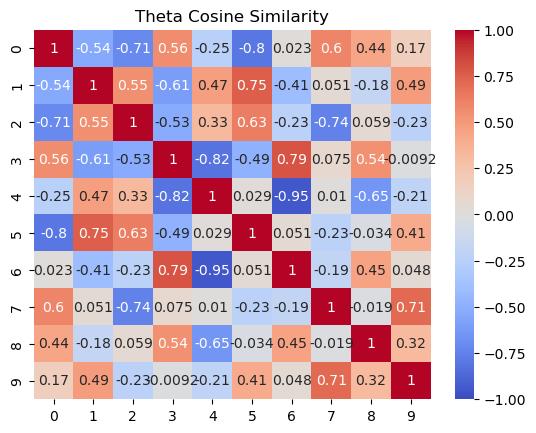

In [35]:
theta_cosine_similarity = cosine_similarity(theta, theta)
sns.heatmap(theta_similarity, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Theta Cosine Similarity")
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

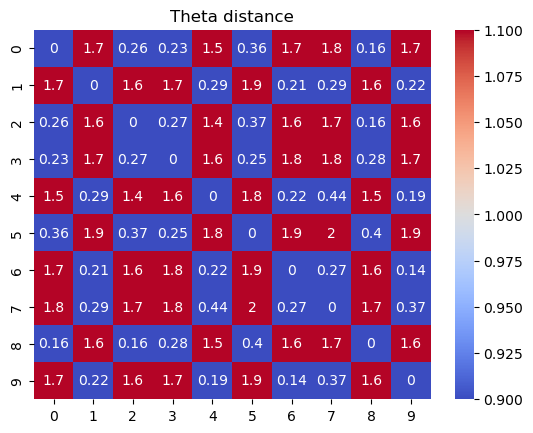

In [36]:
from sklearn.metrics import pairwise_distances

theta_array = np.vstack(theta)
theta_dist = pairwise_distances(theta_array, metric="euclidean")
sns.heatmap(theta_dist, annot=True, cmap='coolwarm', vmin=1, vmax=1)
plt.title("Theta distance")
plt.show

In [38]:
def save_quadratics_to_jsonl(filepath, Gamma, theta, labels, config=None):
    record = {
        "labels": np.asarray(labels, dtype=int).tolist(),
        "theta_list": [np.asarray(t, dtype=float).tolist() for t in theta],
        "gamma_list": [np.asarray(g, dtype=float).tolist() for g in Gamma],
    }

    if config is not None:
        record["config"] = config

    with open(filepath, "w", encoding="utf-8") as f:
        f.write(json.dumps(record) + "\n")

config = {
    "n": 10,
    "p": 5,
    "K": 2,
    "mode": "both",
    "theta_sep": 1.0,
    "theta_noise": 0.01,
    "gamma_noise": 0.01,
    "eig_floor": 1.0,
    "balanced": True,
    "low": -1.0,
    "high": 1.0,
    "seed": 0,
}

save_quadratics_to_jsonl(
    "2_clustered_quadratics_mix.jsonl",
    Gamma,
    theta,
    labels,
    config=config,
)

## Cluster Function from Set1.mat

In [39]:
def sample_theta_noise(rng, p, theta_noise, noise_type="gaussian"):
    if noise_type == "gaussian":
        return theta_noise * rng.normal(size=p)
    elif noise_type == "uniform":
        return rng.uniform(-theta_noise, theta_noise, size=p)
    else:
        raise ValueError("noise_type must be 'gaussian' or 'uniform'")


def sample_gamma_noise(rng, p, gamma_noise, noise_type="gaussian"):
    if noise_type == "gaussian":
        E = gamma_noise * rng.normal(size=(p, p))
    elif noise_type == "uniform":
        E = rng.uniform(-gamma_noise, gamma_noise, size=(p, p))
    else:
        raise ValueError("noise_type must be 'gaussian' or 'uniform'")

    return 0.5 * (E + E.T)

In [40]:
def generate_from_anchor_pool(
    theta_pool,
    gamma_pool,
    anchor_indices,
    n_functions,
    theta_noise=0.1,
    gamma_noise=0.1,
    eig_floor=1.0,
    noise_type="gaussian",
    shuffle=True,
    seed=None,
):

    rng = np.random.default_rng(seed)

    K = len(anchor_indices)
    if K == 0:
        raise ValueError("need one base centre")

    theta_proto = []
    Gamma_proto = []

    for idx in anchor_indices:
        theta_proto.append(np.asarray(theta_pool[idx], dtype=float).copy())
        Gamma_proto.append(
            make_spd(np.asarray(gamma_pool[idx], dtype=float).copy(), eig_floor=eig_floor)
        )

    counts = [n_functions // K] * K # get the number of member for each cluster
    for i in range(n_functions % K):
        counts[i] += 1

    p = theta_proto[0].shape[0]

    Gamma = []
    theta = []
    labels = []


    # adding small noise for each function
    for k in range(K):
        for _ in range(counts[k]):
            theta_i = theta_proto[k] + sample_theta_noise(rng=rng, p=p, theta_noise=theta_noise, noise_type=noise_type)

            Gamma_i = Gamma_proto[k] + sample_gamma_noise(rng=rng, p=p, gamma_noise=gamma_noise, noise_type=noise_type)
            Gamma_i = make_spd(Gamma_i, eig_floor=eig_floor)

            theta.append(theta_i)
            Gamma.append(Gamma_i)
            labels.append(k)

    labels = np.array(labels, dtype=int)

    if shuffle:
        perm = rng.permutation(len(labels))
        labels = labels[perm]
        theta = [theta[i] for i in perm]
        Gamma = [Gamma[i] for i in perm]

    return Gamma, theta, labels, Gamma_proto, theta_proto, counts

In [41]:
gamma_pool = [np.asarray(g, dtype=float) for g in data["Phi"][0]]
theta_pool = [np.asarray(t).reshape(-1) for t in data["theta"][0]]

In [42]:
# len(gamma_pool)

In [43]:
# 1 cluster

Gamma_1c, theta_1c, labels_1c, Gamma_proto_1c, theta_proto_1c, counts_1c = generate_from_anchor_pool(
    theta_pool=theta_pool,
    gamma_pool=gamma_pool,
    anchor_indices=[0],
    n_functions=10,
    theta_noise=0.1,
    gamma_noise=0.1,
    eig_floor=1.0,
    noise_type="gaussian",
    shuffle=True,
    seed=0,
)

In [44]:
# 2 cluster

Gamma_2c, theta_2c, labels_2c, Gamma_proto_2c, theta_proto_2c, counts_2c = generate_from_anchor_pool(
    theta_pool=theta_pool,
    gamma_pool=gamma_pool,
    anchor_indices=[0, 2],
    n_functions=10,
    theta_noise=0.1,
    gamma_noise=0.1,
    eig_floor=1.0,
    noise_type="gaussian",
    shuffle=True,
    seed=1,
)

In [115]:
# 3 cluster

Gamma_3c, theta_3c, labels_3c, Gamma_proto_3c, theta_proto_3c, counts_3c = generate_from_anchor_pool(
    theta_pool=theta_pool,
    gamma_pool=gamma_pool,
    # anchor_indices=[0, 2, 5],
    anchor_indices=[0, 2, 3],
    n_functions=10,
    theta_noise=0.1,
    gamma_noise=0.1,
    eig_floor=1.0,
    noise_type="gaussian",
    shuffle=True,
    seed=2,
)

In [116]:
# save_quadratics_to_jsonl(
#     "set1_three_cluster.jsonl",
#     Gamma_3c,
#     theta_3c,
#     labels_3c,
#     config={
#         "source": "Set1.mat",
#         "anchor_indices": [0, 2, 3],
#         "n_functions": 10,
#         "cluster_sizes": counts_3c,
#         "theta_noise": 0.1,
#         "gamma_noise": 0.1,
#         "eig_floor": 1.0,
#         "noise_type": "gaussian",
#         "seed": 0,
#     },
# )

## Case 1: 1 Cluter

In [50]:
Gamma_c1_dist = pairwise_distance(np.array(Gamma_1c), metric='riemann')
print(Gamma_c1_dist.shape)
print(Gamma_c1_dist)

(10, 10)
[[4.69455020e-15 3.18177504e-01 3.54351676e-01 3.23898160e-01
  2.83778127e-01 2.14774981e-01 2.98788486e-01 2.46112189e-01
  2.97951085e-01 3.01266265e-01]
 [3.18177504e-01 4.40466206e-15 4.27577020e-01 4.07561224e-01
  3.09525592e-01 3.11657195e-01 3.14856780e-01 2.97316263e-01
  3.36273781e-01 2.27216647e-01]
 [3.54351676e-01 4.27577020e-01 5.06582978e-15 1.93440226e-01
  2.82823802e-01 3.02621209e-01 3.44735248e-01 2.79299893e-01
  2.89664501e-01 3.84966937e-01]
 [3.23898160e-01 4.07561224e-01 1.93440226e-01 2.93737402e-15
  3.09092595e-01 3.03860618e-01 3.21387737e-01 2.51341882e-01
  2.31949027e-01 3.52181597e-01]
 [2.83778127e-01 3.09525592e-01 2.82823802e-01 3.09092595e-01
  4.73897498e-15 3.03334154e-01 3.70354264e-01 2.62422191e-01
  2.50718376e-01 2.21592587e-01]
 [2.14774981e-01 3.11657195e-01 3.02621209e-01 3.03860618e-01
  3.03334154e-01 4.71027738e-15 3.49212989e-01 2.60377843e-01
  3.13735612e-01 3.23823280e-01]
 [2.98788486e-01 3.14856780e-01 3.44735248e-01 3.

<function matplotlib.pyplot.show(close=None, block=None)>

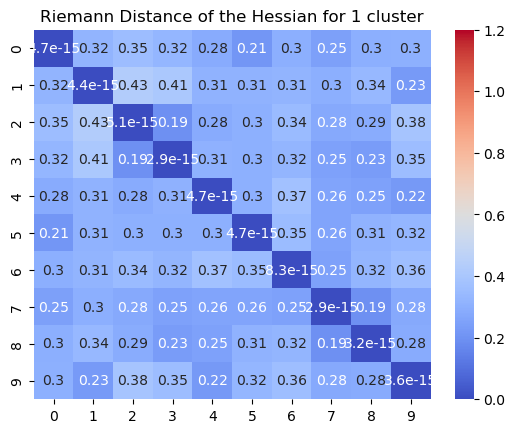

In [51]:
sns.heatmap(Gamma_c1_dist, annot=True, cmap='coolwarm', vmin=0, vmax=1.2)
plt.title("Riemann Distance of the Hessian for 1 cluster")
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

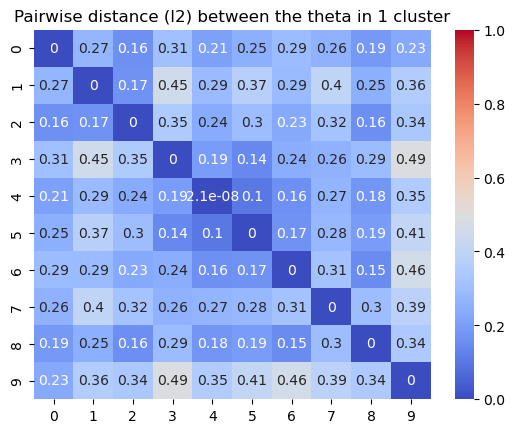

In [57]:
# compute the l2 distance between the theta
theta_1c_dist = pairwise_distances(theta_1c)
sns.heatmap(theta_1c_dist, annot=True, cmap='coolwarm',vmin=0, vmax=1)
plt.title("Pairwise distance (l2) between the theta in 1 cluster")
plt.show

## Cluster 2 data

In [58]:
Gamma_2c_dist = pairwise_distance(np.array(Gamma_2c), metric='riemann')
print(Gamma_2c_dist.shape)
print(Gamma_2c_dist)

(10, 10)
[[2.75997067e-15 1.72866487e+00 1.88039944e+00 2.23291588e-01
  1.82453842e+00 2.00488740e-01 1.84866494e+00 1.74009003e+00
  2.03257848e-01 2.99434314e-01]
 [1.72866487e+00 5.14549746e-15 2.79650234e-01 1.67438537e+00
  2.41643954e-01 1.68460291e+00 2.65210640e-01 1.96816908e-01
  1.67184864e+00 1.63913353e+00]
 [1.88039944e+00 2.79650234e-01 3.99063022e-15 1.83190978e+00
  1.53700550e-01 1.83510402e+00 1.84178145e-01 2.26146262e-01
  1.83044454e+00 1.80164999e+00]
 [2.23291588e-01 1.67438537e+00 1.83190978e+00 3.62823874e-15
  1.77777282e+00 2.03679296e-01 1.79290440e+00 1.69678143e+00
  1.91101837e-01 1.98316384e-01]
 [1.82453842e+00 2.41643954e-01 1.53700550e-01 1.77777282e+00
  3.10862447e-15 1.77597208e+00 1.97510606e-01 1.75177030e-01
  1.77328978e+00 1.74126335e+00]
 [2.00488740e-01 1.68460291e+00 1.83510402e+00 2.03679296e-01
  1.77597208e+00 4.80099256e-15 1.79961274e+00 1.69515670e+00
  1.80474430e-01 2.61740484e-01]
 [1.84866494e+00 2.65210640e-01 1.84178145e-01 1.

<function matplotlib.pyplot.show(close=None, block=None)>

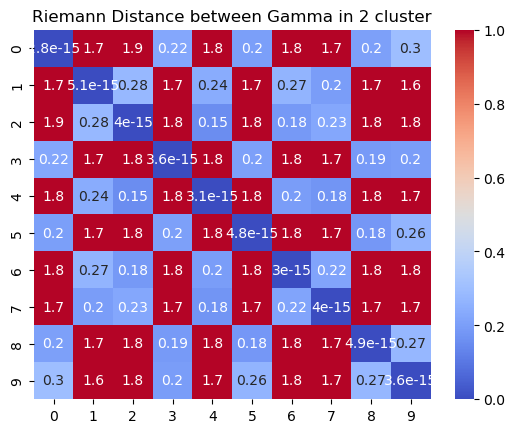

In [121]:
sns.heatmap(Gamma_2c_dist, annot=True, cmap='coolwarm', vmin=0, vmax=1)
plt.title("Riemann Distance between Gamma in 2 cluster")
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

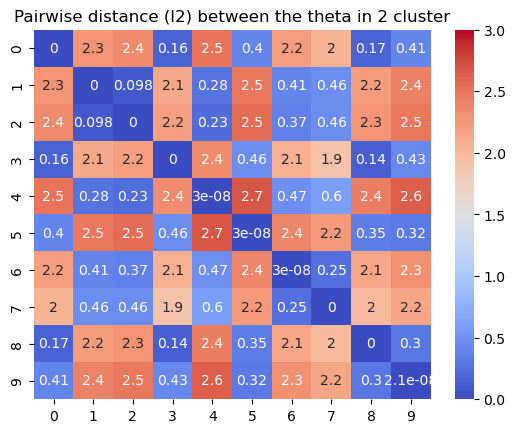

In [62]:
# theta distance in two cluster
theta_2c_dist = pairwise_distances(theta_2c)
sns.heatmap(theta_2c_dist, annot=True, cmap='coolwarm',vmin=0, vmax=3)
plt.title("Pairwise distance (l2) between the theta in 2 cluster")
plt.show

## 3. Cluster

<function matplotlib.pyplot.show(close=None, block=None)>

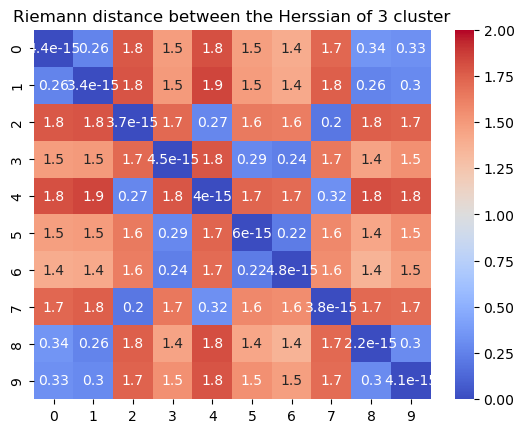

In [117]:
# riemann dist 3 cluster

Gamma_3c_dist = pairwise_distance(np.array(Gamma_3c), metric="riemann")
sns.heatmap(Gamma_3c_dist, annot=True, cmap="coolwarm", vmin=0, vmax=2)
plt.title("Riemann distance between the Herssian of 3 cluster")
plt.show

In [118]:
labels_3c

array([0, 0, 1, 2, 1, 2, 2, 1, 0, 0])

<function matplotlib.pyplot.show(close=None, block=None)>

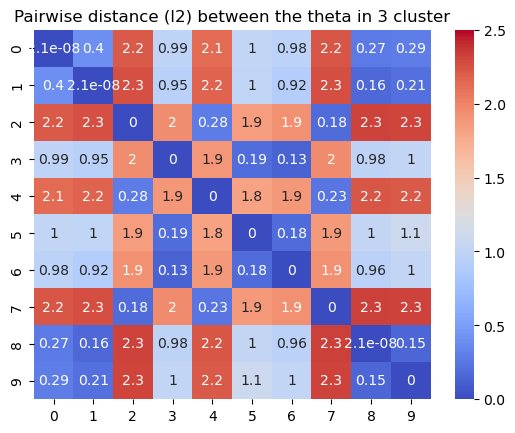

In [119]:
## l2 distance between the theta
theta_3c_dist = pairwise_distances(theta_3c)
sns.heatmap(theta_3c_dist, annot=True, cmap="coolwarm", vmin=0, vmax=2.5)
plt.title("Pairwise distance (l2) between the theta in 3 cluster")
plt.show

In [108]:
### test the jsonl read


def load_agents_from_jsonl(json_path):
    data = pd.read_json(json_path, lines=True)

    gamma_list = data["gamma_list"][0]
    theta_list = data["theta_list"][0]
    labels = data["labels"]

    return np.array(gamma_list), np.array(theta_list), labels


gamma_list_test, gamma_list, labels_test = load_agents_from_jsonl("./set1_one_cluster.jsonl")

In [109]:
pd.read_json("./set1_one_cluster.jsonl", lines=True)

,labels,theta_list,gamma_list,config
0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[[0.045306157547333005, -0.448128007970832, -0...","[[[2.975767474166974, -0.118176560549481, 0.81...","{'source': 'Set1.mat', 'anchor_indices': [0], ..."


In [114]:
gamma_list_test[0].shape

(5, 5)